<a href="https://colab.research.google.com/github/Catarina-c4t/FaceVision-MediaPipe/blob/main/PetVoice_Reconhecimento_de_Voz.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# Instalar a biblioteca para trabalhar com áudios
!pip install librosa


In [2]:
# Instalar as ferramentas necessárias
!apt-get -qq update
!apt-get -qq install -y ffmpeg

!pip -q install librosa scikit-learn matplotlib tensorflow


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


## Enviar o ZIP e preparar o **ambiente**

In [1]:
import os
import shutil
import zipfile
from google.colab import files

# Selecionar o arquivo ZIP
enviados = files.upload()

arquivos_zip = [
    nome for nome in enviados
    if nome.lower().endswith(".zip")
]

if not arquivos_zip:
    raise ValueError("Envie um arquivo ZIP com as gravações.")

zip_path = os.path.join("/content", arquivos_zip[0])

# Preparar pastas novas para não misturar arquivos antigos
pasta_original = "/content/petvoice_originais"
pasta_wav = "/content/petvoice_wav"

for pasta in [pasta_original, pasta_wav]:
    if os.path.exists(pasta):
        shutil.rmtree(pasta)
    os.makedirs(pasta)

# Extrair os arquivos do ZIP
with zipfile.ZipFile(zip_path, "r") as arquivo_zip:
    arquivo_zip.extractall(pasta_original)

print("ZIP extraído com sucesso!")
print("Pasta de origem:", pasta_original)

Saving audiosNovo.zip to audiosNovo.zip
ZIP extraído com sucesso!
Pasta de origem: /content/petvoice_originais


## Converter todos os áudios para **WAV**

In [3]:
import subprocess

extensoes_audio = (
    ".m4a.mp4",
    ".mp4",
    ".m4a",
    ".m4v",
    ".mov",
    ".aac",
    ".wav"
)

total_convertidos = 0
erros_conversao = []

for raiz, pastas, arquivos in os.walk(pasta_original):
    for nome in arquivos:

        nome_minusculo = nome.lower()

        if not nome_minusculo.endswith(extensoes_audio):
            continue

        # O nome da pasta identifica o comando
        comando = os.path.basename(raiz).lower()

        # Ignorar arquivos que não estejam em uma pasta de comando
        if comando not in ["agua", "comida", "brincar", "descanso", "senta"]:
            continue

        entrada = os.path.join(raiz, nome)

        # Remover a extensão completa, inclusive .m4a.mp4
        nome_base = nome
        for extensao in extensoes_audio:
            if nome_minusculo.endswith(extensao):
                nome_base = nome[:-len(extensao)]
                break

        pasta_destino = os.path.join(pasta_wav, comando)
        os.makedirs(pasta_destino, exist_ok=True)

        saida = os.path.join(pasta_destino, nome_base + ".wav")

        # Converter para WAV mono, 22050 Hz
        resultado = subprocess.run(
            [
                "ffmpeg",
                "-y",
                "-i", entrada,
                "-map", "0:a:0",
                "-vn",
                "-ac", "1",
                "-ar", "22050",
                "-c:a", "pcm_s16le",
                saida
            ],
            stdout=subprocess.DEVNULL,
            stderr=subprocess.PIPE,
            text=True
        )

        if resultado.returncode == 0 and os.path.exists(saida):
            total_convertidos += 1
        else:
            erros_conversao.append((entrada, resultado.stderr[-500:]))

print("Áudios convertidos:", total_convertidos)
print("Arquivos com erro:", len(erros_conversao))

if erros_conversao:
    print("\nAlguns arquivos que não puderam ser convertidos:")
    for nome, erro in erros_conversao[:10]:
        print("\nArquivo:", nome)
        print(erro)

Áudios convertidos: 177
Arquivos com erro: 0


## **Conferir a quantidade por comando**

In [4]:
comandos = ["agua", "comida", "brincar", "descanso", "senta"]

print("QUANTIDADE DE ÁUDIOS WAV\n")

for comando in comandos:
    pasta = os.path.join(pasta_wav, comando)

    if os.path.exists(pasta):
        quantidade = sum(
            1 for nome in os.listdir(pasta)
            if nome.lower().endswith(".wav")
        )
    else:
        quantidade = 0

    print(f"{comando}: {quantidade} arquivos")

QUANTIDADE DE ÁUDIOS WAV

agua: 39 arquivos
comida: 35 arquivos
brincar: 33 arquivos
descanso: 35 arquivos
senta: 35 arquivos


## Extrair as características dos áudios usando **MFCC**

In [5]:
import librosa
import numpy as np

caracteristicas = []
rotulos = []
arquivos_processados = []
erros_leitura = []

for comando in comandos:
    pasta = os.path.join(pasta_wav, comando)

    if not os.path.exists(pasta):
        continue

    for nome in sorted(os.listdir(pasta)):
        if not nome.lower().endswith(".wav"):
            continue

        caminho = os.path.join(pasta, nome)

        try:
            audio, sr = librosa.load(
                caminho,
                sr=22050,
                mono=True
            )

            # Ignorar arquivos vazios ou muito curtos
            if len(audio) < int(0.2 * sr):
                erros_leitura.append(caminho)
                continue

            # Extrair 13 MFCCs
            mfcc = librosa.feature.mfcc(
                y=audio,
                sr=sr,
                n_mfcc=13
            )

            # Resumir cada MFCC pela média e desvio-padrão
            media = np.mean(mfcc, axis=1)
            desvio = np.std(mfcc, axis=1)

            vetor = np.concatenate([media, desvio])

            caracteristicas.append(vetor)
            rotulos.append(comando)
            arquivos_processados.append(caminho)

        except Exception as erro:
            erros_leitura.append(caminho)
            print(f"Erro ao ler {nome}: {erro}")

X = np.array(caracteristicas)
y = np.array(rotulos)

print("\nPreparação concluída!")
print("Áudios aproveitados:", len(X))
print("Quantidade de características por áudio:", X.shape[1])
print("Áudios ignorados ou com erro:", len(erros_leitura))

print("\nQuantidade por categoria:")
for comando in comandos:
    print(f"{comando}: {np.sum(y == comando)}")


Preparação concluída!
Áudios aproveitados: 177
Quantidade de características por áudio: 26
Áudios ignorados ou com erro: 0

Quantidade por categoria:
agua: 39
comida: 35
brincar: 33
descanso: 35
senta: 35


## Separar os dados em treinamento e **teste**

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Converter os nomes das categorias em números
codificador = LabelEncoder()
y_numerico = codificador.fit_transform(y)

# Separar treinamento e teste
X_treino_bruto, X_teste_bruto, y_treino, y_teste = train_test_split(
    X,
    y_numerico,
    test_size=0.25,
    random_state=42,
    stratify=y_numerico
)

# Padronizar os dados sem usar o conjunto de teste para aprender parâmetros
padronizador = StandardScaler()

X_treino = padronizador.fit_transform(X_treino_bruto)
X_teste = padronizador.transform(X_teste_bruto)

print("Categorias:", list(codificador.classes_))
print("Gravações para treinamento:", len(X_treino))
print("Gravações para teste:", len(X_teste))
print("Características por áudio:", X_treino.shape[1])

Categorias: [np.str_('agua'), np.str_('brincar'), np.str_('comida'), np.str_('descanso'), np.str_('senta')]
Gravações para treinamento: 132
Gravações para teste: 45
Características por áudio: 26


## Construir e treinar a rede **neural**

In [8]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Facilitar a reprodução do experimento
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

numero_caracteristicas = X_treino.shape[1]
numero_classes = len(codificador.classes_)

modelo = Sequential([
    Input(shape=(numero_caracteristicas,)),
    Dense(64, activation="relu"),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(numero_classes, activation="softmax")
])

modelo.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

parada_antecipada = EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True
)

historico = modelo.fit(
    X_treino,
    y_treino,
    epochs=100,
    batch_size=8,
    validation_split=0.2,
    callbacks=[parada_antecipada],
    verbose=1
)

Epoch 1/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.2190 - loss: 1.5914 - val_accuracy: 0.3704 - val_loss: 1.4523
Epoch 2/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3905 - loss: 1.3548 - val_accuracy: 0.5185 - val_loss: 1.2718
Epoch 3/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6000 - loss: 1.1933 - val_accuracy: 0.7778 - val_loss: 1.1128
Epoch 4/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6952 - loss: 1.0377 - val_accuracy: 0.8889 - val_loss: 0.9621
Epoch 5/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7810 - loss: 0.8995 - val_accuracy: 0.9259 - val_loss: 0.8115
Epoch 6/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8381 - loss: 0.7490 - val_accuracy: 0.9630 - val_loss: 0.6641
Epoch 7/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8762 - loss: 0.6338 - val_accuracy: 0.9630 - val_loss: 0.5379
Epoch 8/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9048 - loss: 0.5313 - val_accuracy: 0.9630 - 

## **Construir e treinar a rede neural**

In [9]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Facilitar a reprodução do experimento
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

numero_caracteristicas = X_treino.shape[1]
numero_classes = len(codificador.classes_)

modelo = Sequential([
    Input(shape=(numero_caracteristicas,)),
    Dense(64, activation="relu"),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(numero_classes, activation="softmax")
])

modelo.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

parada_antecipada = EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True
)

historico = modelo.fit(
    X_treino,
    y_treino,
    epochs=100,
    batch_size=8,
    validation_split=0.2,
    callbacks=[parada_antecipada],
    verbose=1
)

Epoch 1/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.2190 - loss: 1.5914 - val_accuracy: 0.3704 - val_loss: 1.4523
Epoch 2/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3905 - loss: 1.3548 - val_accuracy: 0.5185 - val_loss: 1.2718
Epoch 3/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6000 - loss: 1.1933 - val_accuracy: 0.7778 - val_loss: 1.1128
Epoch 4/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6952 - loss: 1.0377 - val_accuracy: 0.8889 - val_loss: 0.9621
Epoch 5/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7810 - loss: 0.8995 - val_accuracy: 0.9259 - val_loss: 0.8115
Epoch 6/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8381 - loss: 0.7490 - val_accuracy: 0.9630 - val_loss: 0.6641
Epoch 7/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8762 - loss: 0.6338 - val_accuracy: 0.9630 - val_loss: 0.5379
Epoch 8/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9048 - loss: 0.5313 - val_accuracy: 0.9630 -

# **Avaliar a eficácia do PetVoice**

In [10]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Previsões no conjunto de teste
probabilidades = modelo.predict(X_teste, verbose=0)
previsoes = np.argmax(probabilidades, axis=1)

# Calcular acurácia
acuracia = accuracy_score(y_teste, previsoes)

print(f"Acurácia no teste: {acuracia * 100:.2f}%")

print("\nRelatório de classificação:\n")

print(
    classification_report(
        y_teste,
        previsoes,
        labels=np.arange(numero_classes),
        target_names=codificador.classes_,
        zero_division=0
    )
)

Acurácia no teste: 91.11%

Relatório de classificação:

              precision    recall  f1-score   support

        agua       0.91      1.00      0.95        10
     brincar       0.80      1.00      0.89         8
      comida       0.89      0.89      0.89         9
    descanso       1.00      1.00      1.00         9
       senta       1.00      0.67      0.80         9

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45



## **Criar a matriz de confusão**

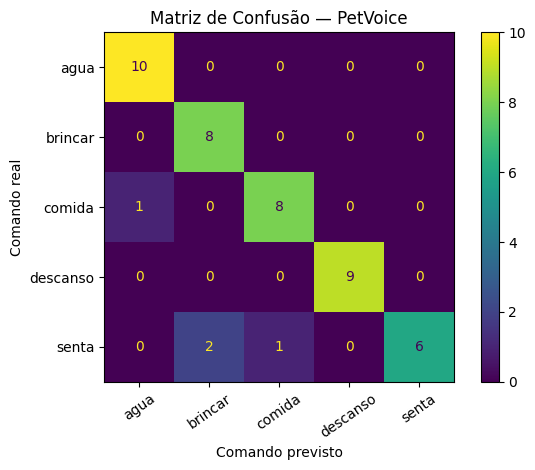

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

matriz = confusion_matrix(
    y_teste,
    previsoes,
    labels=np.arange(numero_classes)
)

grafico = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=codificador.classes_
)

grafico.plot(values_format="d")
plt.title("Matriz de Confusão — PetVoice")
plt.xlabel("Comando previsto")
plt.ylabel("Comando real")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

## **Visualizar o treinamento**

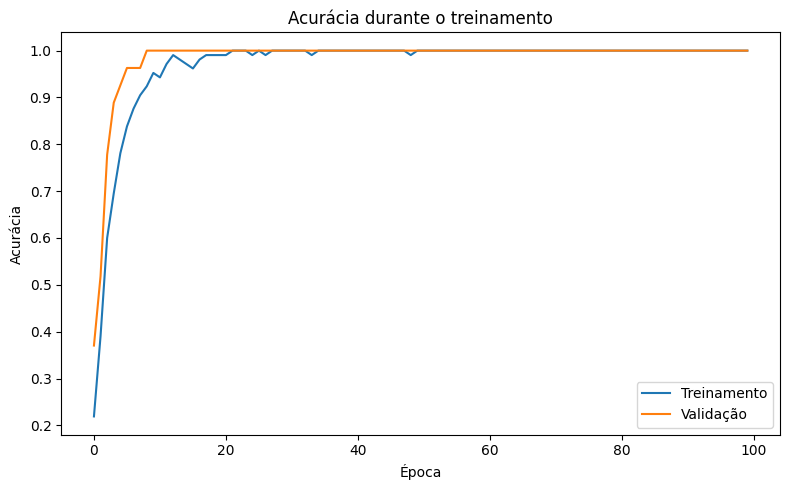

In [12]:
plt.figure(figsize=(8, 5))
plt.plot(historico.history["accuracy"], label="Treinamento")
plt.plot(historico.history["val_accuracy"], label="Validação")
plt.title("Acurácia durante o treinamento")
plt.xlabel("Época")
plt.ylabel("Acurácia")
plt.legend()
plt.tight_layout()
plt.show()

## **perda**

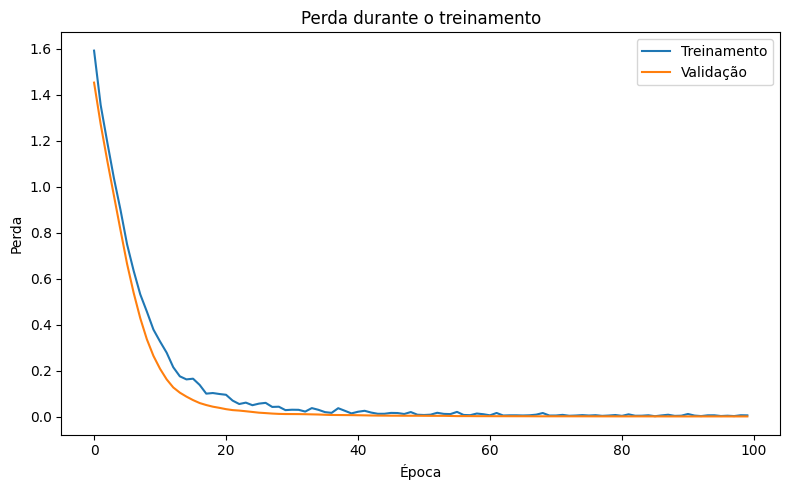

In [13]:
plt.figure(figsize=(8, 5))
plt.plot(historico.history["loss"], label="Treinamento")
plt.plot(historico.history["val_loss"], label="Validação")
plt.title("Perda durante o treinamento")
plt.xlabel("Época")
plt.ylabel("Perda")
plt.legend()
plt.tight_layout()
plt.show()

## Testar uma gravação **nova**

In [14]:
# Enviar uma gravação nova
enviados_teste = files.upload()

arquivo_novo = next(iter(enviados_teste.keys()))
caminho_novo = os.path.join("/content", arquivo_novo)

# Carregar o áudio
audio_novo, sr_novo = librosa.load(
    caminho_novo,
    sr=22050,
    mono=True
)

if len(audio_novo) < int(0.2 * sr_novo):
    raise ValueError("A gravação está vazia ou é curta demais.")

# Extrair as mesmas características do treinamento
mfcc_novo = librosa.feature.mfcc(
    y=audio_novo,
    sr=sr_novo,
    n_mfcc=13
)

media_nova = np.mean(mfcc_novo, axis=1)
desvio_novo = np.std(mfcc_novo, axis=1)

vetor_novo = np.concatenate([media_nova, desvio_novo]).reshape(1, -1)

# Aplicar o mesmo padronizador
vetor_novo = padronizador.transform(vetor_novo)

# Fazer a previsão
probabilidades_novas = modelo.predict(vetor_novo, verbose=0)[0]

indice = np.argmax(probabilidades_novas)
comando_previsto = codificador.inverse_transform([indice])[0]
confianca = probabilidades_novas[indice] * 100

print("Comando reconhecido:", comando_previsto)
print(f"Confiança estimada: {confianca:.2f}%")

print("\nPontuação por comando:")
for nome, prob in zip(codificador.classes_, probabilidades_novas):
    print(f"{nome}: {prob * 100:.2f}%")

Saving Gravando.mp4 to Gravando.mp4


/tmp/ipykernel_2673/4034570809.py:8: UserWarning: PySoundFile failed. Trying audioread instead.
  audio_novo, sr_novo = librosa.load(
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


Comando reconhecido: senta
Confiança estimada: 99.71%

Pontuação por comando:
agua: 0.00%
brincar: 0.00%
comida: 0.29%
descanso: 0.00%
senta: 99.71%


# **teste 2**

In [15]:
# Enviar uma gravação nova
enviados_teste = files.upload()

arquivo_novo = next(iter(enviados_teste.keys()))
caminho_novo = os.path.join("/content", arquivo_novo)

# Carregar o áudio
audio_novo, sr_novo = librosa.load(
    caminho_novo,
    sr=22050,
    mono=True
)

if len(audio_novo) < int(0.2 * sr_novo):
    raise ValueError("A gravação está vazia ou é curta demais.")

# Extrair as mesmas características do treinamento
mfcc_novo = librosa.feature.mfcc(
    y=audio_novo,
    sr=sr_novo,
    n_mfcc=13
)

media_nova = np.mean(mfcc_novo, axis=1)
desvio_novo = np.std(mfcc_novo, axis=1)

vetor_novo = np.concatenate([media_nova, desvio_novo]).reshape(1, -1)

# Aplicar o mesmo padronizador
vetor_novo = padronizador.transform(vetor_novo)

# Fazer a previsão
probabilidades_novas = modelo.predict(vetor_novo, verbose=0)[0]

indice = np.argmax(probabilidades_novas)
comando_previsto = codificador.inverse_transform([indice])[0]
confianca = probabilidades_novas[indice] * 100

print("Comando reconhecido:", comando_previsto)
print(f"Confiança estimada: {confianca:.2f}%")

print("\nPontuação por comando:")
for nome, prob in zip(codificador.classes_, probabilidades_novas):
    print(f"{nome}: {prob * 100:.2f}%")

Saving Gravando (3).mp4 to Gravando (3).mp4


/tmp/ipykernel_2673/4034570809.py:8: UserWarning: PySoundFile failed. Trying audioread instead.
  audio_novo, sr_novo = librosa.load(
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


Comando reconhecido: comida
Confiança estimada: 99.49%

Pontuação por comando:
agua: 0.00%
brincar: 0.00%
comida: 99.49%
descanso: 0.47%
senta: 0.03%


## **Salvar o modelo treinado**

In [16]:
import pickle

modelo.save("/content/petvoice.keras")

with open("/content/petvoice_preprocessamento.pkl", "wb") as arquivo:
    pickle.dump(
        {
            "padronizador": padronizador,
            "codificador": codificador
        },
        arquivo
    )

print("Modelo e pré-processamento salvos com sucesso!")

Modelo e pré-processamento salvos com sucesso!


## **grava audio do comando**

In [20]:

from IPython.display import display, Javascript
from google.colab import output
from base64 import b64decode
import librosa
import numpy as np
import os

# Gravar pelo microfone do navegador
def gravar_audio(duracao=3):
    js = Javascript("""
    async (duracao) => {
      const stream = await navigator.mediaDevices.getUserMedia({audio: true});
      const recorder = new MediaRecorder(stream);
      const partes = [];

      recorder.ondataavailable = e => partes.push(e.data);
      recorder.start();

      await new Promise(resolve => setTimeout(resolve, duracao * 1000));
      recorder.stop();

      await new Promise(resolve => recorder.onstop = resolve);

      stream.getTracks().forEach(track => track.stop());

      const blob = new Blob(partes);
      const buffer = await blob.arrayBuffer();
      const bytes = new Uint8Array(buffer);

      let binario = '';
      bytes.forEach(b => binario += String.fromCharCode(b));
      return btoa(binario);
    }
    """)

    dados = output.eval_js(f"({js.data})( {duracao} )")
    caminho = "/content/comando_microfone.webm"

    with open(caminho, "wb") as arquivo:
        arquivo.write(b64decode(dados))

    return caminho


print("Clique em Permitir quando o navegador pedir acesso ao microfone.")
print("Prepare-se para falar um comando!")

caminho_audio = gravar_audio(3)
print("Gravação concluída!")


Clique em Permitir quando o navegador pedir acesso ao microfone.
Prepare-se para falar um comando!
Gravação concluída!


## **mostra resultado com a IA**

In [21]:

# Converter a gravação para as características usadas no treinamento

audio, sr = librosa.load(
    caminho_audio,
    sr=22050,
    mono=True
)

if len(audio) < int(0.2 * sr):
    raise ValueError("Áudio muito curto. Tente gravar novamente.")

mfcc = librosa.feature.mfcc(
    y=audio,
    sr=sr,
    n_mfcc=13
)

media = np.mean(mfcc, axis=1)
desvio = np.std(mfcc, axis=1)

caracteristicas = np.concatenate(
    [media, desvio]
).reshape(1, -1)

# Padronizar como fizemos no treinamento
caracteristicas = padronizador.transform(caracteristicas)

# A rede neural prevê o comando
probabilidades = modelo.predict(
    caracteristicas,
    verbose=0
)[0]

indice = np.argmax(probabilidades)
comando = codificador.inverse_transform([indice])[0]
confianca = probabilidades[indice] * 100

print("🐾 PETVOICE")
print("Comando reconhecido:", comando.upper())
print(f"Pontuação do modelo: {confianca:.1f}%")

# Resposta correspondente ao comando
respostas = {
    "agua": "Verifique se o seu animal tem água fresca disponível! 💧",
    "comida": "Vamos conferir se o seu animal está alimentado! 🍖",
    "brincar": "Hora de brincar com seu bichinho! 🎾",
    "descanso": "Prepare um lugar tranquilo para seu animal descansar! 💤",
    "senta": "Comando senta reconhecido! Hora de praticar com carinho! 🐶"
}

print("\nResposta:", respostas.get(
    comando,
    "Comando reconhecido."
))


/tmp/ipykernel_2673/18078014.py:3: UserWarning: PySoundFile failed. Trying audioread instead.
  audio, sr = librosa.load(
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


🐾 PETVOICE
Comando reconhecido: SENTA
Pontuação do modelo: 99.7%

Resposta: Comando senta reconhecido! Hora de praticar com carinho! 🐶


In [ ]:
# @title

# Importar as bibliotecas necessárias

import os
import librosa
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from tensorflow import keras
from tensorflow.keras import layers

print("Bibliotecas carregadas!")
print("TensorFlow:", tf.__version__)
print("Librosa:", librosa.__version__)
